In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import json
import torch

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay )
from IPython.display import display
from scipy.stats import binomtest
from matplotlib.patches import Patch
from pathlib import Path
from sentence_transformers import SentenceTransformer

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
DATA_DIR = PROJECT_ROOT / "data" / "processed"

SPLITS = ["stratified", "project_grouped"]
MODELS = ["tfidf", "semantic"]

print("Project directory:", PROJECT_ROOT)
device = "cuda" if torch.cuda.is_available() else "cpu"

Project directory: d:\uOttawa\Fall_26\CSI5187\project


In [2]:
comparison = pd.read_csv(RESULTS_DIR / "metrics" / "test_comparison.csv")

display(comparison.round(4))

# Present macro-F1 in a comparison table
f1_comparison = comparison.pivot(index="split", columns="model", values="macro_f1")

f1_comparison["MPNet - TF-IDF"] = (f1_comparison["semantic"] - f1_comparison["tfidf"])

print("\nMacro-F1 Comparison:")
display(f1_comparison.round(4))

,split,model,accuracy,macro_f1
0,stratified,tfidf,0.7273,0.7147
1,stratified,semantic,0.7244,0.7214
2,project_grouped,tfidf,0.7910,0.7839
3,project_grouped,semantic,0.7373,0.7353



Macro-F1 Comparison:


model,semantic,tfidf,MPNet - TF-IDF
split,,,
project_grouped,0.7353,0.7839,-0.0486
stratified,0.7214,0.7147,0.0067


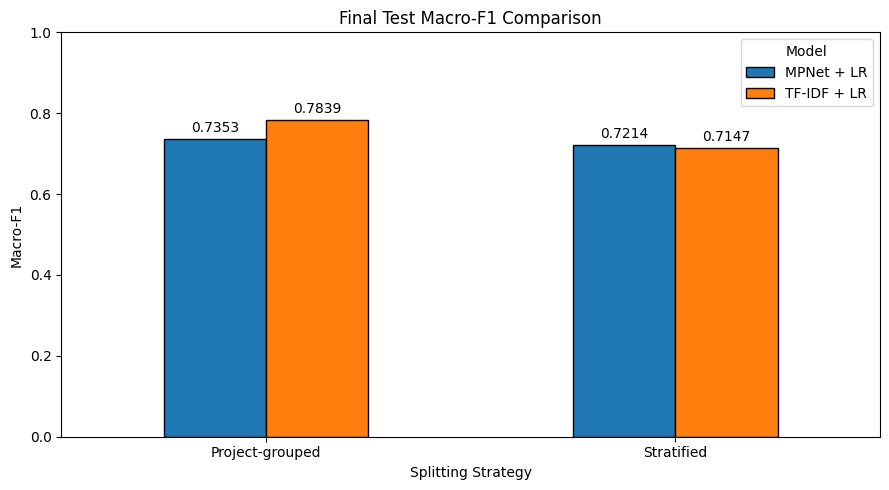

In [3]:
plot_data = comparison.pivot(index="split", columns="model", values="macro_f1")

plot_data = plot_data.rename(
    columns={
        "tfidf": "TF-IDF + LR",
        "semantic": "MPNet + LR"
    },
    index={
        "stratified": "Stratified",
        "project_grouped": "Project-grouped"
    }
)

ax = plot_data.plot(kind="bar", figsize=(9, 5), edgecolor="black", rot=0)

ax.set_title("Final Test Macro-F1 Comparison")
ax.set_xlabel("Splitting Strategy")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [4]:
baseline_results = []

for split_type in SPLITS:

    test_df = pd.read_csv(DATA_DIR / split_type / "test.csv")

    y_true = test_df["label"]
    y_pred = np.zeros(len(y_true), dtype=int)

    baseline_results.append({
        "split": split_type,
        "model": "majority_baseline",
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score( y_true, y_pred, average="macro", zero_division=0)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(4))

,split,model,accuracy,macro_f1
0,stratified,majority_baseline,0.5682,0.3623
1,project_grouped,majority_baseline,0.5678,0.3622


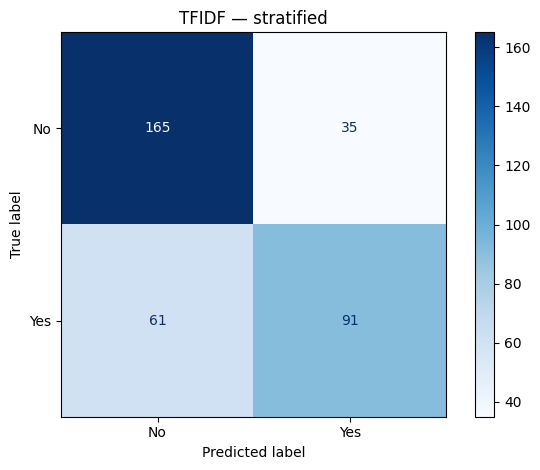

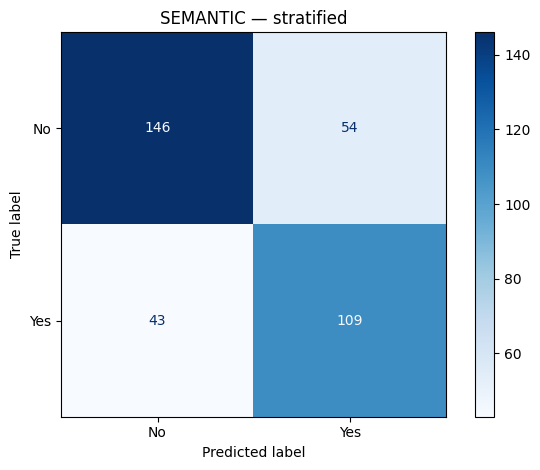

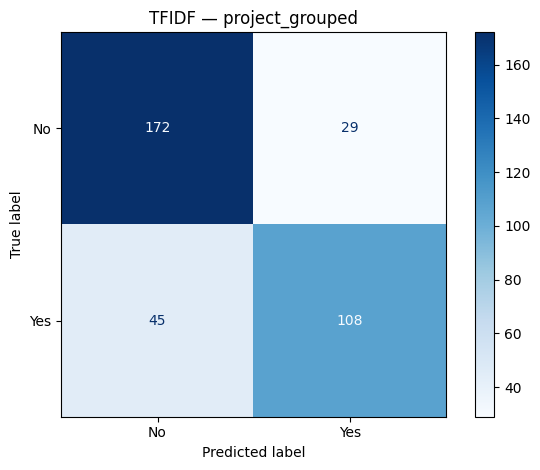

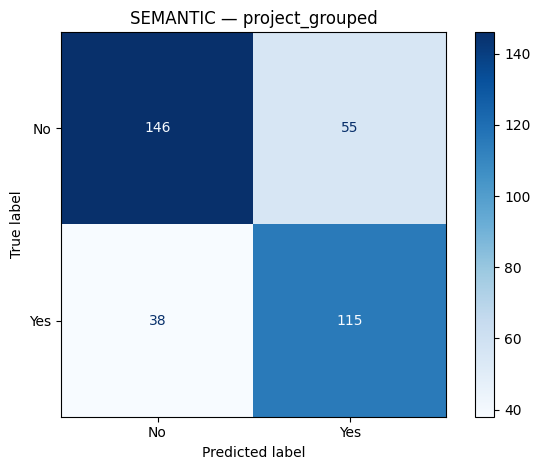

In [5]:
for split_type in SPLITS:

    for model_type in MODELS:

        predictions = pd.read_csv(RESULTS_DIR / "predictions" / split_type / f"{model_type}_predictions.csv")
        cm = confusion_matrix(predictions["label"], predictions["prediction"], labels=[0, 1])

        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"])

        disp.plot(cmap="Blues", values_format="d")

        plt.title(f"{model_type.upper()} — {split_type}")

        plt.tight_layout()
        plt.show()

In [6]:
positive_results = []

for split_type in SPLITS:

    for model_type in MODELS:

        df_pred = pd.read_csv(RESULTS_DIR / "predictions" / split_type / f"{model_type}_predictions.csv")

        positive_results.append({"split": split_type, "model": model_type,
            "precision_yes": precision_score( df_pred["label"],df_pred["prediction"],pos_label=1, zero_division=0),
            "recall_yes": recall_score(df_pred["label"],df_pred["prediction"],pos_label=1,zero_division=0),
            "f1_yes": f1_score(df_pred["label"],df_pred["prediction"],pos_label=1, zero_division=0)
        })

positive_df = pd.DataFrame(positive_results)

display(positive_df.round(4))

,split,model,precision_yes,recall_yes,f1_yes
0,stratified,tfidf,0.7222,0.5987,0.6547
1,stratified,semantic,0.6687,0.7171,0.6921
2,project_grouped,tfidf,0.7883,0.7059,0.7448
3,project_grouped,semantic,0.6765,0.7516,0.7121


In [7]:
for split_type in SPLITS:

    disagreements = pd.read_csv(RESULTS_DIR / "error_analysis" / split_type / "model_disagreements.csv")

    print(f"\nSplit: {split_type}")
    print("Total disagreements:", len(disagreements))

    sample = disagreements.sample(n=min(15, len(disagreements)), random_state=42)

    display(sample[["bodyText","label","tfidf_prediction","semantic_prediction"]])


Split: stratified
Total disagreements: 115


,bodyText,label,tfidf_prediction,semantic_prediction
81,Maybe parseOrigin is better?,1,0,1
4,Suggested change ...,1,1,0
40,should we add a metric to count the number of ...,0,0,1
69,untested,0,0,1
10,Please use AssertJ,1,0,1
45,& should also be translatable.,0,0,1
70,This would be easier to understand if you do: ...,1,1,0
66,"Again, the question is grammatically incorrect...",1,0,1
47,Remember to add comments for these classes in ...,1,0,1
11,This doesn't seem to be used.,1,0,1



Split: project_grouped
Total disagreements: 83


,bodyText,label,tfidf_prediction,semantic_prediction
30,Ditto,0,1,0
0,@gemmellr I saw an email from you asking about...,0,0,1
22,@martinezmatias a rotten assertion,0,0,1
31,Why is this second arg an array?,0,0,1
18,Thanks again for adapting the code! It seems w...,1,0,1
28,My suggestion is to remove this field and inst...,0,0,1
10,Is this to assign the name with the predicate?...,0,0,1
53,Code after this line does not appear anywhere ...,0,0,1
4,shouldn't be static,0,0,1
12,The pattern s == null || s.isEmpty() ? Optiona...,0,0,1


In [8]:
# Load and validate the final reviewed qualitative annotations

annotation_path = (RESULTS_DIR / "error_analysis"/ "qualitative_annotation_reviewed.csv")
annotations = pd.read_csv(annotation_path)

# Validate sample size and unique records

assert len(annotations) == 60
assert not annotations.duplicated(subset=["split", "id"]).any()

# Validate category distribution

expected_categories = pd.MultiIndex.from_product(
    [SPLITS,
    [ "tfidf_only_correct", "mpnet_only_correct","both_incorrect"]
    ],
    names=["split", "error_category"]
)

distribution = annotations.groupby(["split", "error_category"]).size()
assert distribution.index.difference( expected_categories).empty
distribution = distribution.reindex(expected_categories, fill_value=0)
assert distribution.eq(10).all()

# Verify annotations against current model predictions

for split_type in SPLITS:
    current = pd.read_csv( RESULTS_DIR / "error_analysis" / split_type / "all_predictions.csv")
    subset = annotations[annotations["split"].eq(split_type)]

    verified = subset.merge(
        current[["id","label", "tfidf_prediction","semantic_prediction"]],
        on="id",
        how="left",
        suffixes=("_reviewed", "_current"),
        validate="one_to_one",
        indicator=True
    )

    assert verified["_merge"].eq("both").all()

    for column in ["label","tfidf_prediction","semantic_prediction"]:
        assert verified[ f"{column}_reviewed"].eq(verified[f"{column}_current"]).all(), f"Outdated annotations: {split_type}, {column}"

# Validate annotation completeness

for column in ["linguistic_characteristic","analysis_notes"]:
    assert annotations[column].notna().all()
    assert annotations[column].str.strip().ne("").all()

# Display annotation summary

print("Qualitative annotations validated successfully.")
print("Total annotated comments:", len(annotations))

print("\nAnnotation distribution:")

display(pd.crosstab(annotations["split"],annotations["error_category"]))

# Linguistic characteristic frequencies

characteristics = (annotations["linguistic_characteristic"].str.split(";").explode().str.strip())

characteristic_counts = characteristics.value_counts()

print("\nLinguistic characteristic frequencies:")

display(characteristic_counts)

Qualitative annotations validated successfully.
Total annotated comments: 60

Annotation distribution:


error_category,both_incorrect,mpnet_only_correct,tfidf_only_correct
split,,,
project_grouped,10,10,10
stratified,10,10,10



Linguistic characteristic frequencies:


linguistic_characteristic
Code-specific terminology     44
Implicit understandability    24
Context-dependent             22
Short/ambiguous               16
Explicit understandability     8
Documentation-related          4
Name: count, dtype: int64

In [9]:
# Implicit versus explicit understandability analysis

raw_dataset_path = (PROJECT_ROOT / "data" / "raw" / "dataset.tsv")
raw_dataset = pd.read_csv(raw_dataset_path, sep="\t")
type_column = "Implicit or Explicit?"
label_column = "RQ1 - Understandability?"

# Inspect annotation coverage among positive comments

positive_raw = raw_dataset[raw_dataset[label_column].eq("Yes")].copy()
print("Annotation distribution among positive comments:")

display(positive_raw[type_column].fillna("Unannotated").value_counts())

# Retain original dataset annotations for matching

annotation_metadata = raw_dataset[["id","project","bodyText",label_column,type_column]].copy()
assert annotation_metadata["id"].is_unique
implicit_explicit_results = []

for split_type in SPLITS:
    predictions = pd.read_csv( RESULTS_DIR / "error_analysis"/ split_type / "all_predictions.csv")
    # Match test predictions with original annotations
    merged = predictions.merge(annotation_metadata, on="id", how="left",suffixes=("", "_raw"), validate="one_to_one",indicator=True)
    # Verify record-level consistency
    assert len(merged) == len(predictions)
    assert merged["_merge"].eq("both").all()
    assert merged["project"].eq(merged["project_raw"]).all()
    assert merged["bodyText"].eq(merged["bodyText_raw"]).all()
    assert merged["label"].eq(merged[label_column].map({"Yes": 1, "No": 0})).all()

    # Restrict analysis to positive ground-truth comments
    positive_comments = merged[merged["label"].eq(1)].copy()
    positive_comments["understandability_type"] = ( positive_comments[type_column].fillna("Unannotated"))
    for category in ["Implicit","Explicit", "Unannotated"]:
        subset = positive_comments[positive_comments["understandability_type"].eq(category)]
        total = len(subset)
        if total == 0:
            continue

        for model in MODELS:
            prediction_column = f"{model}_prediction"
            detected = int(subset[prediction_column].eq(1).sum())
            missed = total - detected
            implicit_explicit_results.append({
                "split": split_type,
                "category": category,
                "model": model,
                "support": total,
                "true_positives": detected,
                "false_negatives": missed,
                "recall": detected / total
            })

# Construct the final comparison dataframe
implicit_explicit_df = pd.DataFrame(implicit_explicit_results)
print("\nImplicit versus explicit detection performance:")
display(implicit_explicit_df.round(4))

Annotation distribution among positive comments:


Implicit or Explicit?
Unannotated    627
Implicit       335
Explicit        50
Name: count, dtype: int64


Implicit versus explicit detection performance:


,split,category,model,support,true_positives,false_negatives,recall
0,stratified,Implicit,tfidf,49,25,24,0.5102
1,stratified,Implicit,semantic,49,36,13,0.7347
2,stratified,Explicit,tfidf,11,7,4,0.6364
3,stratified,Explicit,semantic,11,7,4,0.6364
4,stratified,Unannotated,tfidf,92,59,33,0.6413
5,stratified,Unannotated,semantic,92,66,26,0.7174
6,project_grouped,Implicit,tfidf,49,30,19,0.6122
7,project_grouped,Implicit,semantic,49,35,14,0.7143
8,project_grouped,Explicit,tfidf,10,6,4,0.6000
9,project_grouped,Explicit,semantic,10,6,4,0.6000


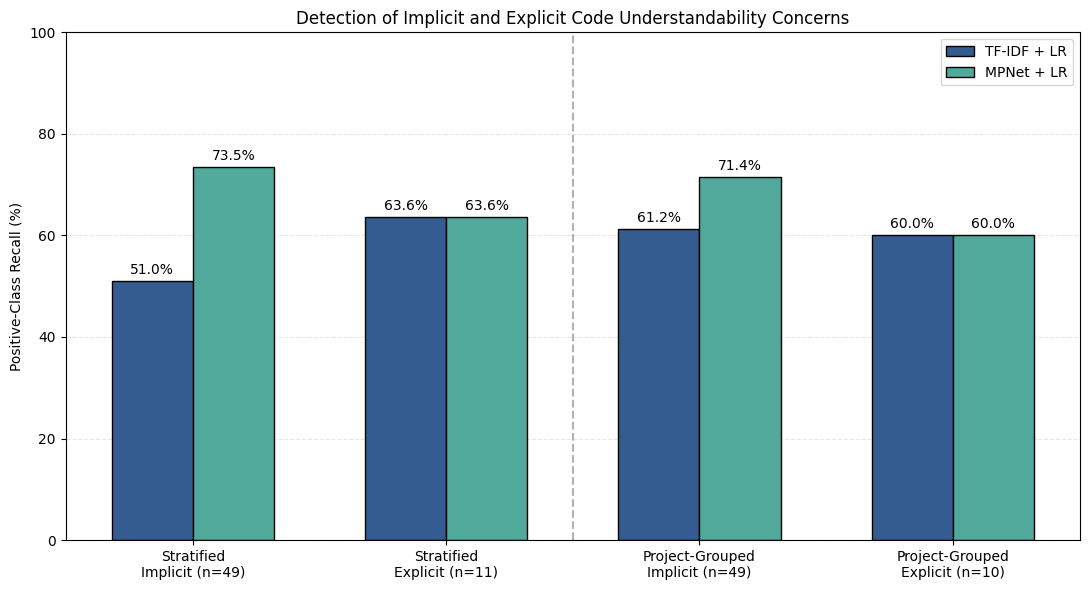

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\implicit_explicit_recall.png
Metrics saved to: d:\uOttawa\Fall_26\CSI5187\project\results\metrics\implicit_explicit_comparison.csv


In [10]:
# Visualize implicit versus explicit detection performance

plot_data = (implicit_explicit_df[implicit_explicit_df["category"].isin(["Implicit", "Explicit"])].pivot(index=["split", "category", "support"],columns="model",values="recall"))
# Maintain a consistent ordering
plot_data = plot_data.reindex([
    ("stratified", "Implicit", 49),
    ("stratified", "Explicit", 11),
    ("project_grouped", "Implicit", 49),
    ("project_grouped", "Explicit", 10)
])

assert plot_data.notna().all().all()

# Construct descriptive x-axis labels

plot_labels = [f"{split.replace('_', '-').title()}\n{category} (n={support})" for split, category, support in plot_data.index]
x = np.arange(len(plot_data))
width = 0.32
fig, ax = plt.subplots(figsize=(11, 6))
tfidf_bars = ax.bar(x - width / 2,plot_data["tfidf"] * 100, width,label="TF-IDF + LR",color="#345C90",edgecolor="black")
semantic_bars = ax.bar( x + width / 2,plot_data["semantic"] * 100,width,label="MPNet + LR",color="#50A99A", edgecolor="black")
ax.bar_label(tfidf_bars, fmt="%.1f%%", padding=3)
ax.bar_label(semantic_bars, fmt="%.1f%%", padding=3)
ax.set_title("Detection of Implicit and Explicit " "Code Understandability Concerns")
ax.set_ylabel("Positive-Class Recall (%)")
ax.set_xticks(x)
ax.set_xticklabels(plot_labels)
ax.set_ylim(0, 100)
ax.axvline( x=1.5,color="gray",linestyle="--",alpha=0.6)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="upper right")
fig.tight_layout()

# Save visualization

figure_path = (RESULTS_DIR / "figures"/ "implicit_explicit_recall.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path,dpi=300, bbox_inches="tight",facecolor="white")
plt.show()

# Save complete subgroup evaluation results

metrics_path = (RESULTS_DIR / "metrics"/ "implicit_explicit_comparison.csv")
metrics_path.parent.mkdir(parents=True, exist_ok=True)
implicit_explicit_df.to_csv(metrics_path,index=False)
print("Figure saved to:", figure_path)
print("Metrics saved to:", metrics_path)

In [11]:
# Duplicate-text sensitivity analysis

duplicate_sensitivity_results = []
overlap_results = []

for split_type in SPLITS:

    split_dir = (PROJECT_ROOT / "data" / "processed" / split_type)
    train_df = pd.read_csv(split_dir / "train.csv")
    val_df = pd.read_csv(split_dir / "validation.csv")
    test_df = pd.read_csv(split_dir / "test.csv")
    predictions = pd.read_csv(RESULTS_DIR / "error_analysis"/ split_type / "all_predictions.csv")
    # Verify consistency with the original test partition
    assert len(predictions) == len(test_df)
    verified = predictions.merge(test_df[["id", "project", "bodyText", "label"]], on="id", how="inner",suffixes=("", "_test"),validate="one_to_one")
    assert len(verified) == len(test_df)
    
    for column in ["project", "bodyText", "label"]:
        assert verified[column].eq(verified[f"{column}_test"]).all()

    # Identify exact comment-text overlap

    train_texts = set(train_df["bodyText"])
    val_texts = set(val_df["bodyText"])

    train_overlap = predictions["bodyText"].isin(train_texts)
    val_overlap = predictions["bodyText"].isin(val_texts)

    combined_overlap = train_overlap | val_overlap

    filtered_predictions = predictions[~combined_overlap].copy()
    overlap_results.append({
        "split": split_type,
        "original_test_size": len(predictions),
        "training_overlap": int(train_overlap.sum()),
        "validation_overlap": int(val_overlap.sum()),
        "overlap_with_both": int((train_overlap & val_overlap).sum()),
        "excluded_comments": int(combined_overlap.sum()),
        "filtered_test_size": len(filtered_predictions)
    })

    # Evaluate both original and filtered test sets

    evaluation_sets = {
        "original": predictions,
        "overlap_excluded": filtered_predictions
    }

    for scenario, subset in evaluation_sets.items():
        for model in MODELS:

            y_true = subset["label"]
            y_pred = subset[f"{model}_prediction"]

            duplicate_sensitivity_results.append({
                "split": split_type,
                "model": model,
                "scenario": scenario,
                "test_size": len(subset),
                "negative_support": int(y_true.eq(0).sum()),
                "positive_support": int(y_true.eq(1).sum()),
                "accuracy": accuracy_score(y_true, y_pred),
                "macro_precision": precision_score(y_true, y_pred,average="macro", zero_division=0),
                "macro_recall": recall_score( y_true, y_pred, average="macro", zero_division=0),
                "macro_f1": f1_score(y_true, y_pred,average="macro", zero_division=0)
            })

# Construct summary dataframes

overlap_df = pd.DataFrame(overlap_results)
duplicate_sensitivity_df = pd.DataFrame(duplicate_sensitivity_results)
print("Cross-partition comment-text overlap:")
display(overlap_df)
print("\nDuplicate-text sensitivity analysis:")
display(duplicate_sensitivity_df.round(4))

# Calculate changes in macro-F1

sensitivity_comparison = duplicate_sensitivity_df.pivot(index=["split", "model"],columns="scenario",values="macro_f1").reset_index()
sensitivity_comparison["macro_f1_change"] = ( sensitivity_comparison["overlap_excluded"] - sensitivity_comparison["original"])
print("\nImpact of excluding overlapping comment texts:")
display(sensitivity_comparison.round(4))

Cross-partition comment-text overlap:


,split,original_test_size,training_overlap,validation_overlap,overlap_with_both,excluded_comments,filtered_test_size
0,stratified,352,5,1,1,5,347
1,project_grouped,354,4,0,0,4,350



Duplicate-text sensitivity analysis:


,split,model,scenario,test_size,negative_support,positive_support,accuracy,macro_precision,macro_recall,macro_f1
0,stratified,tfidf,original,352,200,152,0.7273,0.7262,0.7118,0.7147
1,stratified,semantic,original,352,200,152,0.7244,0.7206,0.7236,0.7214
2,stratified,tfidf,overlap_excluded,347,198,149,0.7233,0.7216,0.7069,0.7098
3,stratified,semantic,overlap_excluded,347,198,149,0.7233,0.7190,0.7219,0.7198
4,project_grouped,tfidf,original,354,201,153,0.7910,0.7905,0.7808,0.7839
5,project_grouped,semantic,original,354,201,153,0.7373,0.7350,0.7390,0.7353
6,project_grouped,tfidf,overlap_excluded,350,200,150,0.7886,0.7876,0.7775,0.7808
7,project_grouped,semantic,overlap_excluded,350,200,150,0.7343,0.7315,0.7358,0.7319



Impact of excluding overlapping comment texts:


scenario,split,model,original,overlap_excluded,macro_f1_change
0,project_grouped,semantic,0.7353,0.7319,-0.0034
1,project_grouped,tfidf,0.7839,0.7808,-0.0031
2,stratified,semantic,0.7214,0.7198,-0.0015
3,stratified,tfidf,0.7147,0.7098,-0.0049


In [12]:
# Export duplicate-text sensitivity analysis results

metrics_dir = RESULTS_DIR / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
overlap_path = (metrics_dir / "cross_partition_text_overlap.csv")
sensitivity_path = (metrics_dir / "duplicate_sensitivity_metrics.csv")
comparison_path = (metrics_dir / "duplicate_sensitivity_comparison.csv")
overlap_df.to_csv(overlap_path,index=False)
duplicate_sensitivity_df.to_csv( sensitivity_path, index=False)
sensitivity_comparison.to_csv( comparison_path, index=False)
print("Cross-partition overlap saved to:")
print(overlap_path)
print("\nDuplicate sensitivity metrics saved to:")
print(sensitivity_path)
print("\nDuplicate sensitivity comparison saved to:")
print(comparison_path)

Cross-partition overlap saved to:
d:\uOttawa\Fall_26\CSI5187\project\results\metrics\cross_partition_text_overlap.csv

Duplicate sensitivity metrics saved to:
d:\uOttawa\Fall_26\CSI5187\project\results\metrics\duplicate_sensitivity_metrics.csv

Duplicate sensitivity comparison saved to:
d:\uOttawa\Fall_26\CSI5187\project\results\metrics\duplicate_sensitivity_comparison.csv


In [13]:
# Statistical significance analysis using exact McNemar's test
ALPHA = 0.05
mcnemar_results = []

for split_type in SPLITS:
    predictions = pd.read_csv(RESULTS_DIR / "error_analysis"/ split_type / "all_predictions.csv")
    assert predictions["id"].is_unique
    
    for column in ["label","tfidf_prediction","semantic_prediction"]:
        assert predictions[column].isin([0, 1]).all()

    # Determine prediction correctness

    tfidf_correct = predictions["tfidf_prediction"].eq(predictions["label"])
    semantic_correct = predictions["semantic_prediction"].eq(predictions["label"])
    # Construct paired contingency table
    both_correct = int((tfidf_correct & semantic_correct).sum())
    tfidf_only = int((tfidf_correct & ~semantic_correct).sum())
    semantic_only = int((~tfidf_correct & semantic_correct).sum())
    both_incorrect = int((~tfidf_correct & ~semantic_correct).sum())
    assert ( both_correct + tfidf_only + semantic_only + both_incorrect == len(predictions))
    discordant_pairs = tfidf_only + semantic_only
    # Exact two-sided McNemar test
    if discordant_pairs == 0:
        p_value = 1.0
    else:
        p_value = binomtest( k=tfidf_only,n=discordant_pairs, p=0.5,alternative="two-sided").pvalue

    mcnemar_results.append({
        "split": split_type,
        "test_size": len(predictions),
        "both_correct": both_correct,
        "tfidf_only_correct": tfidf_only,
        "semantic_only_correct": semantic_only,
        "both_incorrect": both_incorrect,
        "discordant_pairs": discordant_pairs,
        "p_value": p_value,
        "significant_unadjusted": p_value < ALPHA
    })

mcnemar_df = pd.DataFrame(mcnemar_results)

# Holm correction for the two statistical comparisons

p_values = mcnemar_df["p_value"].to_numpy()
order = np.argsort(p_values)
n_tests = len(p_values)

adjusted_sorted = np.minimum( 1.0, np.maximum.accumulate(p_values[order] * (n_tests - np.arange(n_tests))))
adjusted_p_values = np.empty(n_tests)
adjusted_p_values[order] = adjusted_sorted
mcnemar_df["p_value_holm"] = adjusted_p_values
mcnemar_df["significant_adjusted"] = (mcnemar_df["p_value_holm"] < ALPHA)
print("Exact McNemar's test results:")
display(mcnemar_df.round(6))

Exact McNemar's test results:


,split,test_size,both_correct,tfidf_only_correct,semantic_only_correct,both_incorrect,discordant_pairs,p_value,significant_unadjusted,p_value_holm,significant_adjusted
0,stratified,352,198,58,57,39,115,1.000000,False,1.00000,False
1,project_grouped,354,229,51,32,42,83,0.047525,True,0.09505,False


In [14]:
# Paired project-level bootstrap confidence intervals
N_BOOTSTRAP = 10000
BOOTSTRAP_SEED = 42
bootstrap_results = []
bootstrap_comparison_results = []
bootstrap_distributions = {}
def macro_f1_from_counts(counts):
    """
    Calculate binary macro-F1 from confusion matrix counts.
    Column order: TN, FP, FN, TP.
    """
    tn, fp, fn, tp = np.moveaxis( np.asarray(counts, dtype=float), -1, 0)
    denominator_no = 2 * tn + fp + fn
    denominator_yes = 2 * tp + fp + fn
    f1_no = np.divide( 2 * tn, denominator_no, out=np.zeros_like(tn),where=denominator_no != 0)
    f1_yes = np.divide(2 * tp,denominator_yes,out=np.zeros_like(tp),where=denominator_yes != 0)
    return (f1_no + f1_yes) / 2


for split_type in SPLITS:
    predictions = pd.read_csv( RESULTS_DIR / "error_analysis" / split_type / "all_predictions.csv")
    assert predictions["id"].is_unique
    assert predictions["project"].notna().all()

    for column in ["label","tfidf_prediction","semantic_prediction"]:
        assert predictions[column].isin([0, 1]).all()

    # Assign an integer index to each software project

    project_indices, projects = pd.factorize(predictions["project"],sort=True)
    n_projects = len(projects)
    y_true = predictions["label"].to_numpy()

    # Generate identical project samples for both models

    rng = np.random.default_rng(BOOTSTRAP_SEED)
    project_weights = rng.multinomial(n_projects,np.full(n_projects, 1 / n_projects), size=N_BOOTSTRAP)
    assert np.all( project_weights.sum(axis=1) == n_projects)

    # Count ground-truth classes within each project

    project_label_counts = np.zeros((n_projects, 2),dtype=np.int64)
    np.add.at( project_label_counts, (project_indices, y_true),1)
    bootstrap_label_counts = ( project_weights @ project_label_counts)

    # Retain bootstrap samples containing both classes

    valid_samples = (bootstrap_label_counts > 0).all(axis=1)
    valid_iterations = int(valid_samples.sum())
    assert valid_iterations > 0
    project_weights = project_weights[valid_samples]

    print(f"\nSplit: {split_type}")
    print("Test comments:", len(predictions))
    print("Unique test projects:", n_projects)
    print("Bootstrap iterations:", N_BOOTSTRAP)
    print("Valid iterations:", valid_iterations)
    print("Excluded iterations:",N_BOOTSTRAP - valid_iterations)

    observed_scores = {}
    sampled_scores = {}

    for model in MODELS:
        y_pred = predictions[f"{model}_prediction"].to_numpy()

        # Encode confusion matrix positions
        # 0 = TN, 1 = FP, 2 = FN, 3 = TP

        confusion_indices = 2 * y_true + y_pred
        project_counts = np.zeros( (n_projects, 4),dtype=np.int64 )
        np.add.at(project_counts, (project_indices, confusion_indices), 1)
        assert project_counts.sum() == len(predictions)

        # Original observed macro-F1

        observed_f1 = float(macro_f1_from_counts(project_counts.sum(axis=0)))

        # Verify against scikit-learn

        expected_f1 = f1_score( y_true,  y_pred, labels=[0, 1], average="macro",zero_division=0)
        assert np.isclose(observed_f1, expected_f1)

        # Aggregate confusion counts for bootstrap samples

        bootstrap_counts = ( project_weights @ project_counts)
        bootstrap_f1 = macro_f1_from_counts( bootstrap_counts)
        ci_lower, ci_upper = np.percentile(bootstrap_f1, [2.5, 97.5])
        observed_scores[model] = observed_f1
        sampled_scores[model] = bootstrap_f1
        bootstrap_results.append({
            "split": split_type,
            "model": model,
            "test_size": len(predictions),
            "n_projects": n_projects,
            "bootstrap_iterations": valid_iterations,
            "observed_macro_f1": observed_f1,
            "bootstrap_mean": bootstrap_f1.mean(),
            "bootstrap_std": bootstrap_f1.std(ddof=1),
            "ci_lower": ci_lower,
            "ci_upper": ci_upper
        })

    # Calculate paired differences in macro-F1

    observed_difference = ( observed_scores["semantic"] - observed_scores["tfidf"])
    bootstrap_differences = ( sampled_scores["semantic"] - sampled_scores["tfidf"])
    diff_lower, diff_upper = np.percentile( bootstrap_differences, [2.5, 97.5])
    bootstrap_comparison_results.append({
        "split": split_type,
        "n_projects": n_projects,
        "bootstrap_iterations": valid_iterations,
        "observed_difference": observed_difference,
        "bootstrap_mean_difference":
            bootstrap_differences.mean(),
        "ci_lower": diff_lower,
        "ci_upper": diff_upper,
        "ci_excludes_zero": bool(
            diff_lower > 0 or diff_upper < 0
        )
    })

    bootstrap_distributions[split_type] = {
        "tfidf": sampled_scores["tfidf"],
        "semantic": sampled_scores["semantic"],
        "difference": bootstrap_differences
    }

# Construct final result dataframes

bootstrap_df = pd.DataFrame(bootstrap_results)
bootstrap_comparison_df = pd.DataFrame( bootstrap_comparison_results)

print("\nIndividual macro-F1 confidence intervals:")
display(bootstrap_df.round(6))
print("\nPaired macro-F1 difference confidence intervals:")
display(bootstrap_comparison_df.round(6))


Split: stratified
Test comments: 352
Unique test projects: 229
Bootstrap iterations: 10000
Valid iterations: 10000
Excluded iterations: 0

Split: project_grouped
Test comments: 354
Unique test projects: 55
Bootstrap iterations: 10000
Valid iterations: 10000
Excluded iterations: 0

Individual macro-F1 confidence intervals:


,split,model,test_size,n_projects,bootstrap_iterations,observed_macro_f1,bootstrap_mean,bootstrap_std,ci_lower,ci_upper
0,stratified,tfidf,352,229,10000,0.714662,0.713533,0.023905,0.666676,0.759315
1,stratified,semantic,352,229,10000,0.721353,0.720779,0.025403,0.671139,0.769930
2,project_grouped,tfidf,354,55,10000,0.783897,0.783124,0.021192,0.739874,0.823021
3,project_grouped,semantic,354,55,10000,0.735258,0.734586,0.027638,0.680176,0.787955



Paired macro-F1 difference confidence intervals:


,split,n_projects,bootstrap_iterations,observed_difference,bootstrap_mean_difference,ci_lower,ci_upper,ci_excludes_zero
0,stratified,229,10000,0.006691,0.007246,-0.054869,0.071770,False
1,project_grouped,55,10000,-0.048639,-0.048537,-0.096263,0.001579,False


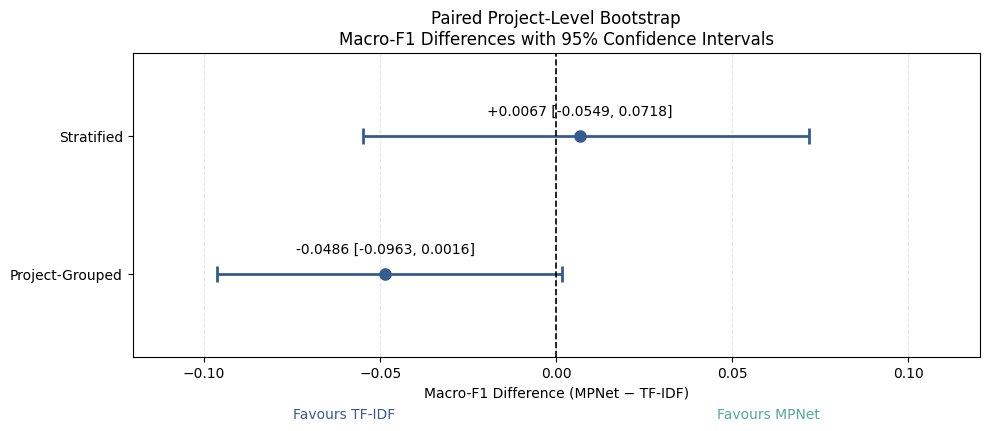

Saved: d:\uOttawa\Fall_26\CSI5187\project\results\metrics\mcnemar_test_results.csv
Records: 2
Saved: d:\uOttawa\Fall_26\CSI5187\project\results\metrics\bootstrap_macro_f1_ci.csv
Records: 4
Saved: d:\uOttawa\Fall_26\CSI5187\project\results\metrics\bootstrap_macro_f1_comparison.csv
Records: 2

Figure saved to:
d:\uOttawa\Fall_26\CSI5187\project\results\figures\bootstrap_macro_f1_difference.png


In [15]:
# Visualize paired macro-F1 confidence intervals

plot_df = (bootstrap_comparison_df.set_index("split").loc[SPLITS].reset_index())
y_positions = np.arange(len(plot_df))
observed = plot_df["observed_difference"].to_numpy()
lower = plot_df["ci_lower"].to_numpy()
upper = plot_df["ci_upper"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.5))

# Plot confidence intervals

ax.hlines(y=y_positions,xmin=lower,xmax=upper,color="#345C90",linewidth=2)
# Add confidence interval end caps
ax.plot(lower,y_positions,"|",color="#345C90",markersize=12,markeredgewidth=2)
ax.plot( upper,y_positions,"|",color="#345C90",markersize=12,markeredgewidth=2)
# Plot observed differences
ax.scatter(observed,y_positions,color="#345C90",s=65,zorder=3)

# Zero-difference reference line

ax.axvline(0,color="black",linestyle="--",linewidth=1.2)

# Annotate observed differences and confidence intervals

for i, row in plot_df.iterrows():

    annotation = (f'{row["observed_difference"]:+.4f} 'f'[{row["ci_lower"]:.4f}, 'f'{row["ci_upper"]:.4f}]')
    ax.annotate(annotation,xy=(row["observed_difference"], i),xytext=(0, 15),textcoords="offset points",ha="center",fontsize=10)

ax.set_yticks(y_positions)
ax.set_yticklabels([split.replace("_", "-").title() for split in plot_df["split"]])
ax.set_ylim(-0.6, len(plot_df) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("Macro-F1 Difference (MPNet − TF-IDF)")

ax.set_title("Paired Project-Level Bootstrap\n" 
             "Macro-F1 Differences with 95% Confidence Intervals")

# Set symmetrical axis limits

limit = max(abs(lower).max(), abs(upper).max()) * 1.25
ax.set_xlim(-limit, limit)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.text(0.25, -0.20,"Favours TF-IDF",transform=ax.transAxes,ha="center",color="#345C90")
ax.text(0.75, -0.20,"Favours MPNet",transform=ax.transAxes,ha="center", color="#50A99A")
fig.tight_layout()

# Save confidence interval visualization

figure_path = ( RESULTS_DIR / "figures" / "bootstrap_macro_f1_difference.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path,dpi=300,bbox_inches="tight",facecolor="white")
plt.show()

# Export statistical analysis results

metrics_dir = RESULTS_DIR / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
statistical_outputs = {
    "mcnemar_test_results.csv": mcnemar_df,
    "bootstrap_macro_f1_ci.csv": bootstrap_df,
    "bootstrap_macro_f1_comparison.csv": bootstrap_comparison_df
}

for filename, dataframe in statistical_outputs.items():
    output_path = metrics_dir / filename
    dataframe.to_csv(output_path,index=False)
    print(f"Saved: {output_path}")
    print(f"Records: {len(dataframe)}")

print("\nFigure saved to:")
print(figure_path)

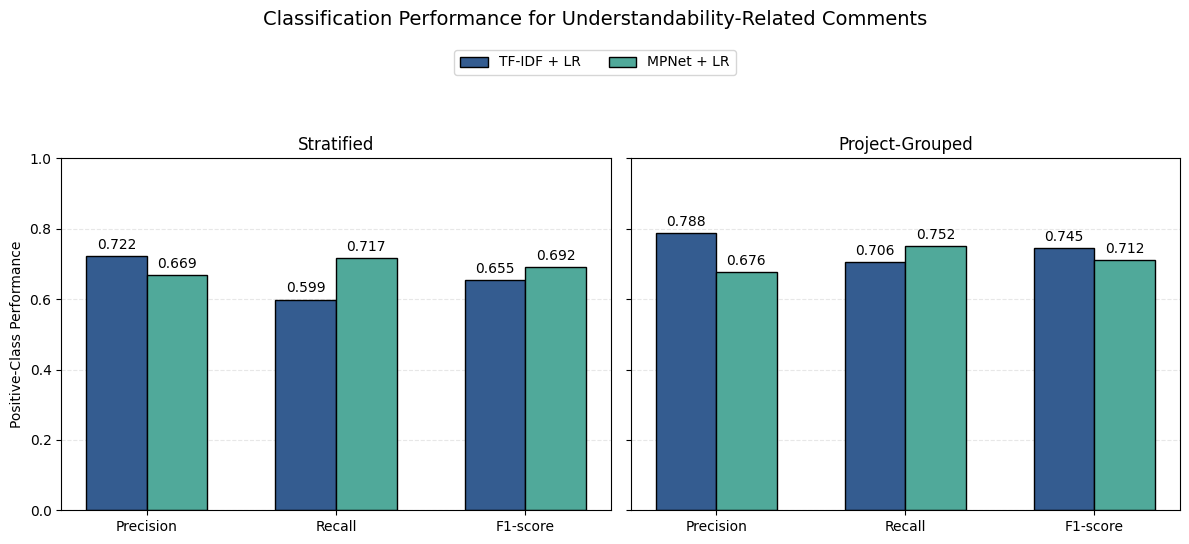

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\positive_class_performance.png


,split,model,Precision,Recall,F1-score
0,stratified,tfidf,0.7222,0.5987,0.6547
1,stratified,semantic,0.6687,0.7171,0.6921
2,project_grouped,tfidf,0.7883,0.7059,0.7448
3,project_grouped,semantic,0.6765,0.7516,0.7121


In [16]:
# Positive-class performance comparison

positive_plot_results = []

for split_type in SPLITS:
    predictions = pd.read_csv(RESULTS_DIR / "error_analysis" / split_type / "all_predictions.csv" )
    y_true = predictions["label"]

    for model in MODELS:
        y_pred = predictions[f"{model}_prediction"]
        positive_plot_results.append({
            "split": split_type,
            "model": model,
            "Precision": precision_score( y_true, y_pred, pos_label=1, zero_division=0),
            "Recall": recall_score(y_true, y_pred,pos_label=1, zero_division=0),
            "F1-score": f1_score(y_true, y_pred,pos_label=1, zero_division=0)
        })

positive_plot_df = pd.DataFrame(positive_plot_results)
metrics = ["Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
x = np.arange(len(metrics))
width = 0.32

for ax, split_type in zip(axes, SPLITS):
    subset = positive_plot_df[positive_plot_df["split"].eq(split_type)].set_index("model")
    tfidf_bars = ax.bar(x - width / 2,subset.loc["tfidf", metrics].to_numpy(dtype=float),width,label="TF-IDF + LR",color="#345C90",edgecolor="black")
    semantic_bars = ax.bar(x + width / 2,subset.loc["semantic", metrics].to_numpy(dtype=float),width,label="MPNet + LR",color="#50A99A",edgecolor="black")
    ax.bar_label(tfidf_bars, fmt="%.3f", padding=3)
    ax.bar_label(semantic_bars, fmt="%.3f", padding=3)
    ax.set_title(split_type.replace("_", "-").title())
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

axes[0].set_ylabel("Positive-Class Performance")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels,loc="upper center",bbox_to_anchor=(0.5, 0.92), ncol=2)
fig.suptitle("Classification Performance for " "Understandability-Related Comments",fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.84])
figure_path = (RESULTS_DIR / "figures"/ "positive_class_performance.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path,dpi=300,bbox_inches="tight",facecolor="white")
plt.show()
print("Figure saved to:", figure_path)
display(positive_plot_df.round(4))

Linguistic characteristic counts:


split                              stratified                     \
error_category             tfidf_only_correct mpnet_only_correct   
characteristic                                                     
Code-specific terminology                   7                  6   
Implicit understandability                  3                  5   
Context-dependent                           2                  3   
Short/ambiguous                             2                  4   
Explicit understandability                  3                  1   
Documentation-related                       2                  1   

split                                        project_grouped  \
error_category             both_incorrect tfidf_only_correct   
characteristic                                                 
Code-specific terminology               8                  8   
Implicit understandability              5                  3   
Context-dependent                       4                  6   
Short/ambiguous                         2                  3   
Explicit understandability              1                  0   
Documentation-related                   0                  0   

split                                                         
error_category             mpnet_only_correct both_incorrect  
characteristic                                                
Code-specific terminology                   9              6  
Implicit understandability                  6              2  
Context-dependent                           1              6  
Short/ambiguous                             0              5  
Explicit understandability                  3              0  
Documentation-related                       1              0


Total characteristic frequencies:


characteristic
Code-specific terminology     44
Implicit understandability    24
Context-dependent             22
Short/ambiguous               16
Explicit understandability     8
Documentation-related          4
dtype: int64

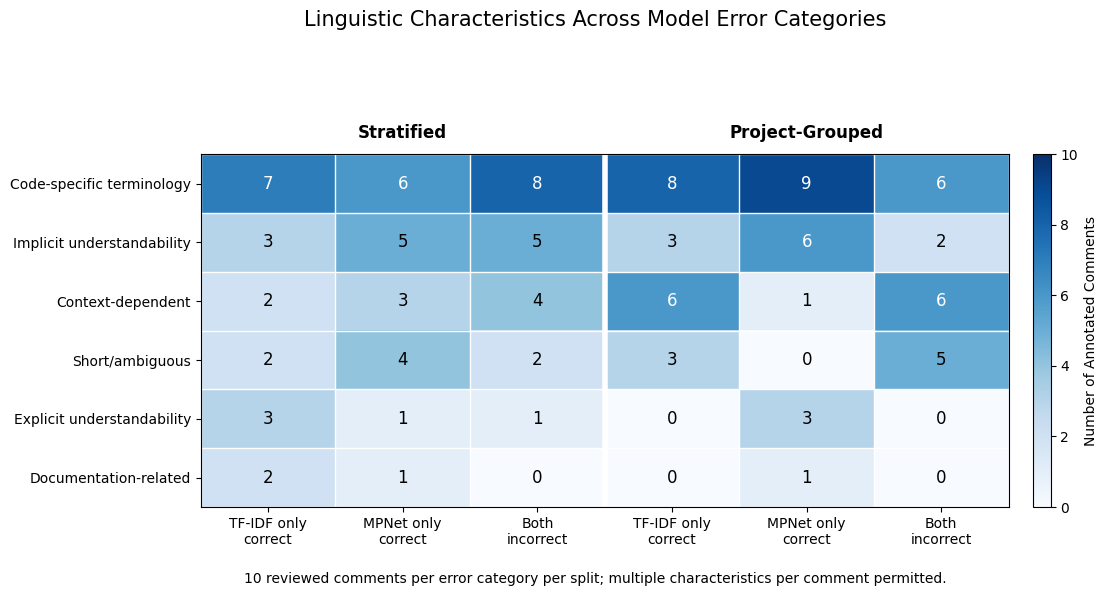

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\linguistic_characteristic_heatmap.png


In [17]:
# Linguistic characteristic heatmap

annotation_path = (RESULTS_DIR / "error_analysis"/ "qualitative_annotation_reviewed.csv")
reviewed_annotations = pd.read_csv(annotation_path)

# Validate annotation sample
assert len(reviewed_annotations) == 60
assert not reviewed_annotations.duplicated(subset=["split", "id"]).any()

characteristic_order = ["Code-specific terminology","Implicit understandability","Context-dependent",
    "Short/ambiguous","Explicit understandability","Documentation-related"]
error_category_order = ["tfidf_only_correct","mpnet_only_correct","both_incorrect"]
expected_groups = pd.MultiIndex.from_product([SPLITS, error_category_order],names=["split", "error_category"])
group_sizes = (reviewed_annotations.groupby(["split", "error_category"]).size().reindex(expected_groups, fill_value=0))
assert group_sizes.eq(10).all()

# Expand multi-label linguistic annotations

expanded_annotations = reviewed_annotations.assign(characteristic=reviewed_annotations["linguistic_characteristic"].str.split(";")).explode("characteristic")
expanded_annotations["characteristic"] = (expanded_annotations["characteristic"].str.strip())

assert expanded_annotations["characteristic"].isin(characteristic_order).all()

# Ensure each characteristic is counted once per comment

expanded_annotations = expanded_annotations.drop_duplicates(subset=["split", "id", "characteristic"])

# Construct linguistic characteristic frequency matrix

linguistic_heatmap_df = pd.crosstab(expanded_annotations["characteristic"],[expanded_annotations["split"],expanded_annotations["error_category"]]).reindex(index=characteristic_order,columns=expected_groups,fill_value=0)

# Validate frequency counts

assert linguistic_heatmap_df.ge(0).all().all()
assert linguistic_heatmap_df.le(10).all().all()
expected_totals = (expanded_annotations["characteristic"].value_counts().reindex(characteristic_order, fill_value=0))
assert np.array_equal(linguistic_heatmap_df.sum(axis=1).to_numpy(),expected_totals.to_numpy())
print("Linguistic characteristic counts:")
display(linguistic_heatmap_df)
print("\nTotal characteristic frequencies:")
display(linguistic_heatmap_df.sum(axis=1))

# Generate heatmap

fig, ax = plt.subplots(figsize=(12, 6))
heatmap_values = linguistic_heatmap_df.to_numpy()
image = ax.imshow(heatmap_values,cmap="Blues",vmin=0,vmax=10,aspect="auto")

# Annotate each heatmap cell

for row in range(heatmap_values.shape[0]):
    for column in range(heatmap_values.shape[1]):
        count = int(heatmap_values[row, column])
        ax.text(column,row,str(count),ha="center",va="center",color="white" if count >= 6 else "black", fontsize=12,fontweight="medium")

# Axis labels
ax.set_yticks(np.arange(len(characteristic_order)))
ax.set_yticklabels(characteristic_order)
column_labels = ["TF-IDF only\ncorrect","MPNet only\ncorrect", "Both\nincorrect"] * len(SPLITS)
ax.set_xticks(np.arange(len(column_labels)))
ax.set_xticklabels(column_labels)

# Add split headings
for i, split_type in enumerate(SPLITS):
    ax.text(i * 3 + 1,1.035,split_type.replace("_", "-").title(),transform=ax.get_xaxis_transform(),ha="center",va="bottom",fontsize=12,fontweight="bold")

# Separate splitting strategies
ax.axvline(2.5,color="white",linewidth=4)

# Add cell boundaries
ax.set_xticks(np.arange(-0.5, len(column_labels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(characteristic_order), 1),minor=True)
ax.grid(which="minor",color="white",linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)

# Colorbar
colorbar = fig.colorbar(image,ax=ax,ticks=np.arange(0, 11, 2),pad=0.025)
colorbar.set_label("Number of Annotated Comments")
fig.suptitle("Linguistic Characteristics Across Model Error Categories",fontsize=15,y=0.98)
fig.text(0.5,0.025,"10 reviewed comments per error category per split; ""multiple characteristics per comment permitted.",ha="center",fontsize=10)
fig.tight_layout(rect=[0, 0.06, 1, 0.88])

# Save visualization
figure_path = (RESULTS_DIR / "figures"/ "linguistic_characteristic_heatmap.png")
figure_path.parent.mkdir(parents=True,exist_ok=True)
fig.savefig(figure_path,dpi=300,bbox_inches="tight",facecolor="white")
plt.show()
print("Figure saved to:", figure_path)

In [18]:
# TF-IDF feature interpretability


TOP_K = 15

feature_importance_results = []
feature_inventory = []

for split_type in SPLITS:

    model_path = (RESULTS_DIR / "models" / split_type/ "tfidf_logistic_regression.joblib")
    model = joblib.load(model_path)

    # Extract fitted feature union and classifier

    feature_union = model.named_steps["features"]
    classifier = model.named_steps["classifier"]
    feature_names = feature_union.get_feature_names_out()
    coefficients = classifier.coef_[0]

    # Validate coefficient and feature alignment

    assert classifier.classes_.tolist() == [0, 1]
    assert classifier.coef_.shape[0] == 1
    assert len(feature_names) == len(coefficients)
    assert np.isfinite(coefficients).all()

    feature_df = pd.DataFrame({"feature": feature_names,"coefficient": coefficients})

    # Separate word and character features
    feature_df["feature_type"] = (feature_df["feature"].str.split("__", n=1).str[0])
    feature_df["ngram"] = (feature_df["feature"].str.split("__", n=1).str[1])
    assert feature_df["feature_type"].isin(["word", "char"]).all()
    print(f"\nExperiment: {split_type}")
    print("Total features:", len(feature_df))
    print("Regularization C:", classifier.C)
    print("Class weight:", classifier.class_weight)
    print("Classifier intercept:", classifier.intercept_[0])

    for feature_type in ["word", "char"]:
        subset = feature_df[feature_df["feature_type"].eq(feature_type)].copy()
        feature_inventory.append({"split": split_type,"feature_type": feature_type,"feature_count": len(subset)})

        # Strongest positive coefficients
        positive_features = (subset[subset["coefficient"].gt(0)].nlargest(TOP_K, "coefficient").copy())
        positive_features["associated_class"] = "Yes"

        # Strongest negative coefficients
        negative_features = ( subset[subset["coefficient"].lt(0)] .nsmallest(TOP_K, "coefficient").copy())
        negative_features["associated_class"] = "No"
        
        for ranked_features in [positive_features, negative_features]:
            ranked_features["split"] = split_type
            ranked_features["rank"] = np.arange(1, len(ranked_features) + 1)
            feature_importance_results.append(ranked_features)
            print(f"\nTop {TOP_K} {feature_type} features "f"associated with "f"{ranked_features['associated_class'].iloc[0]}:")
            display(ranked_features[["rank", "ngram", "coefficient"]].assign(ngram=lambda df: df["ngram"].map(repr)).round(4))

# Construct final result dataframes
feature_importance_df = pd.concat(feature_importance_results,ignore_index=True)
feature_inventory_df = pd.DataFrame(feature_inventory)
print("\nTF-IDF feature inventory:")
display(feature_inventory_df)
print("\nTotal ranked feature records:",len(feature_importance_df))


Experiment: stratified
Total features: 34622
Regularization C: 10.0
Class weight: None
Classifier intercept: -0.11090823988801715

Top 15 word features associated with Yes:


,rank,ngram,coefficient
3047,1,'rename',3.0864
2027,2,'javadoc',2.8005
2181,3,'log',2.4277
2434,4,'name',2.3941
856,5,'comment',2.3861
1917,6,'is redundant',2.3168
2150,7,'link',2.2787
49,8,'a comment',2.2721
4308,9,'variable',2.2497
1426,10,'formatting',2.1997



Top 15 word features associated with No:


,rank,ngram,coefficient
2039,1,'json',-2.4801
4280,2,'using',-2.4718
4471,3,'why',-2.4508
2497,4,'nice',-2.3722
1351,5,'final',-2.1898
1577,6,'header',-2.1741
2512,7,'no',-2.0571
2928,8,'provider',-2.0568
6,9,'1',-1.9917
3042,10,'remove this',-1.9217



Top 15 char features associated with Yes:


,rank,ngram,coefficient
13052,1,'doc',1.7709
4756,2,' * ',1.6252
22997,3,'name ',1.6022
6203,4,' nam',1.4383
6202,5,' na',1.3433
6204,6,' name',1.3360
16006,7,'ere.',1.2901
18625,8,'here.',1.2901
22995,9,'nam',1.2844
22411,10,'mment',1.2684


... (9 outputs left out)

,rank,ngram,coefficient
6747,1,' th',-0.1383
18409,2,'inal',-0.1309
16157,3,'fina',-0.1269
16158,4,'final',-0.1269
18408,5,'ina',-0.1250
21954,6,'nal',-0.1232
16156,7,'fin',-0.1173
31595,8,'test',-0.1160
17623,9,'hy ',-0.1137
33826,10,'why',-0.1137



TF-IDF feature inventory:


,split,feature_type,feature_count
0,stratified,word,4622
1,stratified,char,30000
2,project_grouped,word,4583
3,project_grouped,char,30000



Total ranked feature records: 120


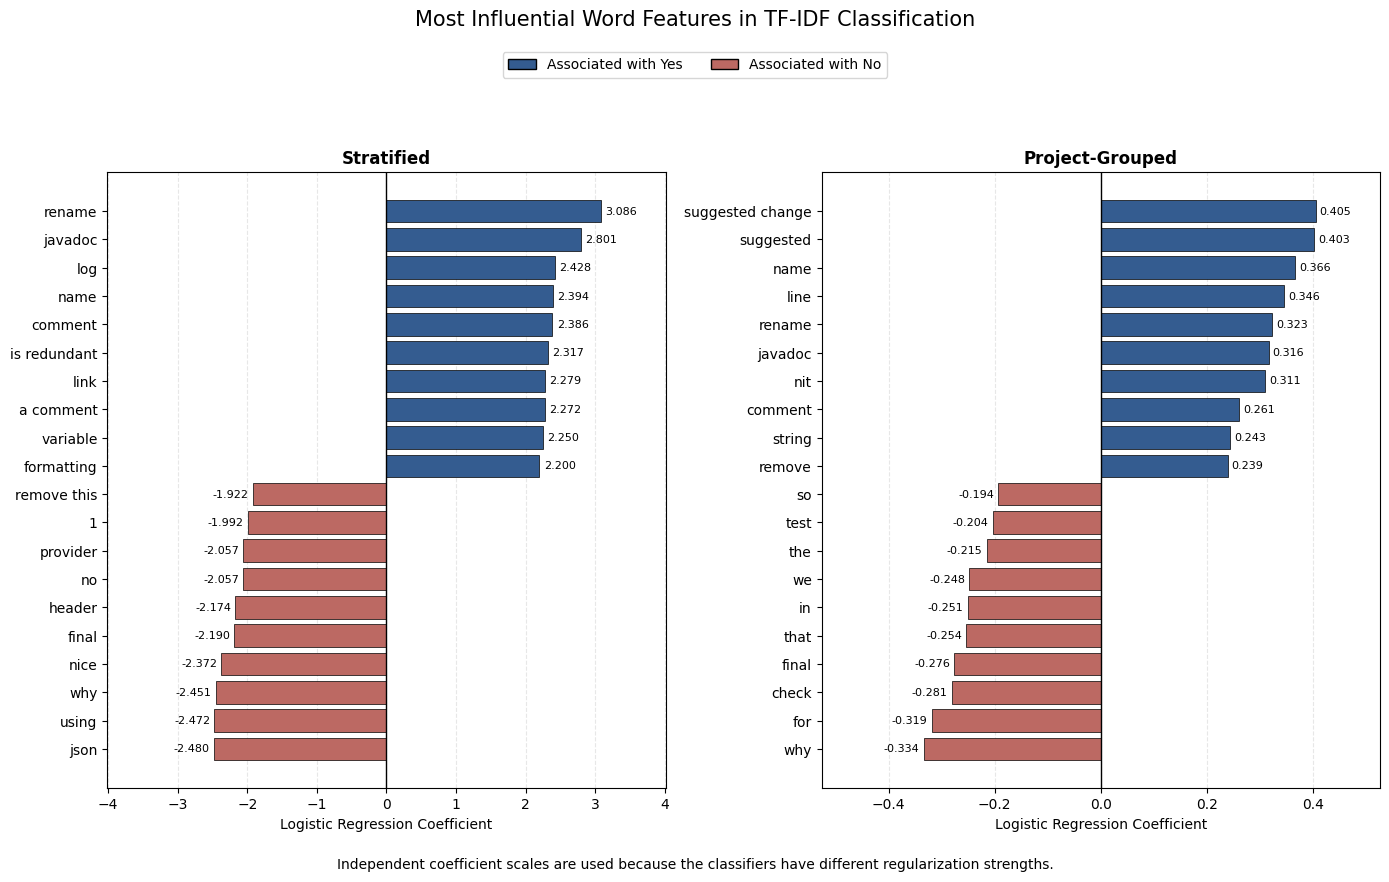

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\tfidf_word_feature_coefficients.png
Feature coefficients saved to: d:\uOttawa\Fall_26\CSI5187\project\results\metrics\tfidf_feature_importance.csv
Feature inventory saved to: d:\uOttawa\Fall_26\CSI5187\project\results\metrics\tfidf_feature_inventory.csv

Ranked feature records: 120


In [19]:
# Visualize the strongest TF-IDF word coefficients

TOP_PLOT = 10
fig, axes = plt.subplots(1, 2,figsize=(14, 9))

for ax, split_type in zip(axes, SPLITS):
    subset = feature_importance_df[ feature_importance_df["split"].eq(split_type) & feature_importance_df["feature_type"].eq("word")].copy()
    positive = (subset[subset["associated_class"].eq("Yes")].nlargest(TOP_PLOT, "coefficient"))
    negative = (subset[subset["associated_class"].eq("No")].nsmallest(TOP_PLOT, "coefficient"))
    plot_features = (pd.concat([positive, negative]).sort_values("coefficient"))
    colors = ["#345C90" if coefficient > 0 else "#BC6963"for coefficient in plot_features["coefficient"]]
    bars = ax.barh( plot_features["ngram"],plot_features["coefficient"],color=colors,edgecolor="black", linewidth=0.5)
    ax.bar_label( bars,fmt="%.3f",padding=3, fontsize=8)
    ax.axvline( 0,color="black",linewidth=1)
    
    # Use an independent scale for each classifier
    limit = (plot_features["coefficient"].abs().max() * 1.30)
    ax.set_xlim(-limit, limit)
    ax.set_title(split_type.replace("_", "-").title(),fontsize=12,fontweight="bold")
    ax.set_xlabel("Logistic Regression Coefficient")
    ax.set_axisbelow(True)
    ax.grid(axis="x",linestyle="--",alpha=0.3)



legend_handles = [
    Patch(facecolor="#345C90",edgecolor="black",label="Associated with Yes"),
    Patch(facecolor="#BC6963",edgecolor="black",label="Associated with No")
]
fig.legend(handles=legend_handles,loc="upper center",bbox_to_anchor=(0.5, 0.94), ncol=2)
fig.suptitle("Most Influential Word Features in ""TF-IDF Classification", fontsize=15)
fig.text(0.5,0.025,"Independent coefficient scales are used because ""the classifiers have different regularization strengths.",ha="center",fontsize=10)
fig.tight_layout(rect=[0, 0.05, 1, 0.88])

# Save visualization
figure_path = (RESULTS_DIR / "figures"/ "tfidf_word_feature_coefficients.png")

figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig( figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Export feature interpretability results

metrics_dir = RESULTS_DIR / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
feature_path = ( metrics_dir / "tfidf_feature_importance.csv")
inventory_path = (metrics_dir / "tfidf_feature_inventory.csv")
feature_importance_df.to_csv(feature_path,index=False)
feature_inventory_df.to_csv(inventory_path,index=False)
print("Figure saved to:", figure_path)
print("Feature coefficients saved to:", feature_path)
print("Feature inventory saved to:", inventory_path)
print("\nRanked feature records:",len(feature_importance_df))

In [20]:
# Decision-threshold optimization curves
embedding_model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2",device=device)
threshold_curve_results = []
threshold_summary_results = []

for split_type in SPLITS:
    val_df = pd.read_csv(PROJECT_ROOT / "data" / "processed"/ split_type / "validation.csv")
    X_val = val_df["bodyText"]
    y_val = val_df["label"].to_numpy()

    for model_type in MODELS:
        model_path = (RESULTS_DIR / "models" / split_type / f"{model_type}_logistic_regression.joblib")
        config_path = (RESULTS_DIR / "metrics" / split_type / f"{model_type}_validation.json")
        classifier = joblib.load(model_path)
        
        with open(config_path, encoding="utf-8") as file:
            config = json.load(file)

        selected_threshold = float(config["best_threshold"])

        # Generate validation features
        if model_type == "tfidf":
            model_input = X_val

        elif model_type == "semantic":
            model_input = embedding_model.encode(
                X_val.tolist(),
                batch_size=32,
                show_progress_bar=True,
                convert_to_numpy=True,
                normalize_embeddings=config.get("normalize_embeddings", False)
            )

        # Obtain positive-class probabilities

        positive_index = list(classifier.classes_).index(1)
        probabilities = classifier.predict_proba(model_input)[:, positive_index]
        assert np.isfinite(probabilities).all()

        # Reconstruct threshold candidates used during training
        unique_probabilities = np.unique(probabilities)
        midpoints = (unique_probabilities[:-1] + unique_probabilities[1:]) / 2

        thresholds = np.unique(np.concatenate([[0.0, 0.5, 1.0, selected_threshold],midpoints]))

        def evaluate_threshold(threshold):
            predictions = (probabilities >= threshold).astype(int)
            return f1_score(y_val,predictions,average="macro",zero_division=0)

        # Calculate validation macro-F1 across thresholds
        scores = np.array([evaluate_threshold(t) for t in thresholds])
        default_f1 = evaluate_threshold(0.5)
        optimized_f1 = evaluate_threshold( selected_threshold)

        # Verify the saved threshold and validation score
        saved_f1 = float(config["validation_macro_f1"])

        assert np.isclose(optimized_f1, saved_f1), (f"Saved validation score mismatch: "f"{split_type}, {model_type}")
        assert np.isclose(optimized_f1, scores.max()), (f"Selected threshold does not reproduce " f"the maximum validation score: "f"{split_type}, {model_type}")
        threshold_summary_results.append({
            "split": split_type,
            "model": model_type,
            "default_threshold": 0.5,
            "selected_threshold": selected_threshold,
            "default_macro_f1": default_f1,
            "optimized_macro_f1": optimized_f1,
            "macro_f1_improvement":optimized_f1 - default_f1
        })
        threshold_curve_results.extend([
            {
                "split": split_type,
                "model": model_type,
                "threshold": threshold,
                "validation_macro_f1": score
            }
            for threshold, score in zip(thresholds, scores)
        ])

threshold_curve_df = pd.DataFrame(threshold_curve_results)
threshold_summary_df = pd.DataFrame(threshold_summary_results)
print("\nDecision-threshold optimization summary:")
display(threshold_summary_df.round(6))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]


Decision-threshold optimization summary:


,split,model,default_threshold,selected_threshold,default_macro_f1,optimized_macro_f1,macro_f1_improvement
0,stratified,tfidf,0.5,0.498472,0.758015,0.761236,0.003221
1,stratified,semantic,0.5,0.482937,0.717011,0.725215,0.008203
2,project_grouped,tfidf,0.5,0.500206,0.714073,0.716700,0.002627
3,project_grouped,semantic,0.5,0.466549,0.725502,0.728716,0.003214


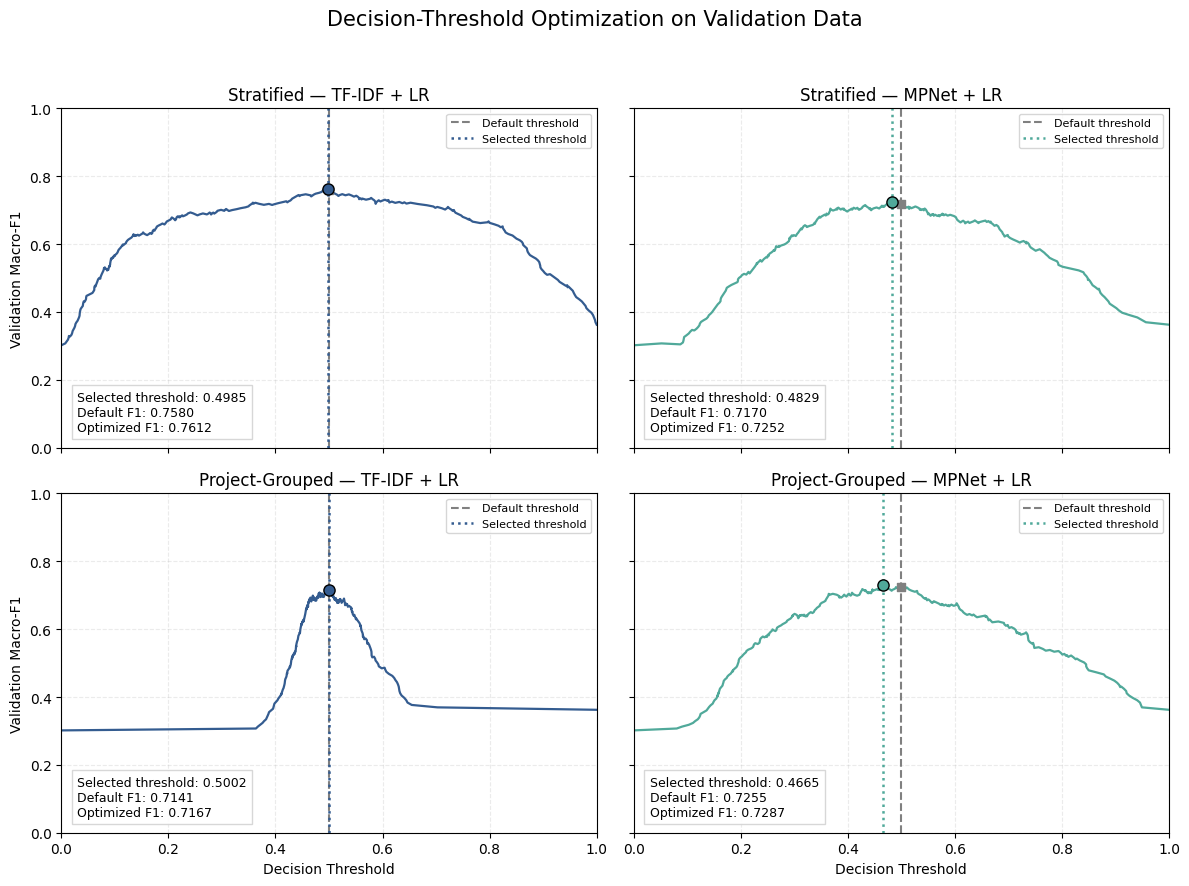

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\decision_threshold_optimization.png
Threshold optimization results saved successfully.


In [21]:
# Visualize and export decision-threshold optimization

fig, axes = plt.subplots(2, 2,figsize=(12, 9),sharex=True,sharey=True)

for i, split_type in enumerate(SPLITS):
    for j, model_type in enumerate(MODELS):
        ax = axes[i, j]
        subset = threshold_curve_df[threshold_curve_df["split"].eq(split_type) & threshold_curve_df["model"].eq(model_type)]
        summary = threshold_summary_df[threshold_summary_df["split"].eq(split_type) & threshold_summary_df["model"].eq(model_type)].iloc[0]
        color = ("#345C90" if model_type == "tfidf" else "#50A99A")
        ax.plot( subset["threshold"],subset["validation_macro_f1"], color=color,linewidth=1.6)

        # Default threshold
        ax.axvline( 0.5, color="gray",linestyle="--",label="Default threshold")

        # Validation-selected threshold
        ax.axvline(summary["selected_threshold"],color=color,linestyle=":",linewidth=1.8, label="Selected threshold")
        ax.scatter( 0.5,summary["default_macro_f1"],color="gray",marker="s",s=40,zorder=4)
        ax.scatter(summary["selected_threshold"],summary["optimized_macro_f1"],color=color,edgecolor="black",s=65,zorder=5)
        model_name = ("TF-IDF + LR" if model_type == "tfidf" else "MPNet + LR")
        ax.set_title(f"{split_type.replace('_', '-').title()}" f" — {model_name}")
        ax.text(
            0.03, 0.05,
            f'Selected threshold: '
            f'{summary["selected_threshold"]:.4f}\n'
            f'Default F1: '
            f'{summary["default_macro_f1"]:.4f}\n'
            f'Optimized F1: '
            f'{summary["optimized_macro_f1"]:.4f}',
            transform=ax.transAxes,
            fontsize=9,
            bbox=dict(facecolor="white",edgecolor="lightgray",alpha=0.9))

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.25, linestyle="--")
        ax.legend(loc="upper right", fontsize=8)

        if i == 1:
            ax.set_xlabel("Decision Threshold")

        if j == 0:
            ax.set_ylabel("Validation Macro-F1")

fig.suptitle("Decision-Threshold Optimization on Validation Data", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.95])
figure_path = (RESULTS_DIR / "figures"/ "decision_threshold_optimization.png")
fig.savefig(figure_path,dpi=300,bbox_inches="tight",facecolor="white")
plt.show()

threshold_curve_df.to_csv( RESULTS_DIR / "metrics"/ "decision_threshold_curves.csv",index=False)
threshold_summary_df.to_csv(RESULTS_DIR / "metrics"/ "decision_threshold_summary.csv", index=False)
print("Figure saved to:", figure_path)
print("Threshold optimization results saved successfully.")

In [22]:
# Consolidate primary and supplementary experiments

SUPPLEMENTARY_DIR = RESULTS_DIR / "supplementary"
ablation_df = pd.read_csv(SUPPLEMENTARY_DIR / "tfidf_ablation" / "ablation_comparison.csv")
controlled_ablation_df = pd.read_csv( SUPPLEMENTARY_DIR / "tfidf_ablation"/ "ablation_controlled_comparison.csv")
hybrid_comparison_df = pd.read_csv(SUPPLEMENTARY_DIR / "hybrid"/ "hybrid_comparison.csv")
hybrid_config_df = pd.read_csv(SUPPLEMENTARY_DIR / "hybrid"/ "hybrid_results.csv")

# Verify expected result dimensions

assert len(ablation_df) == 6
assert len(controlled_ablation_df) == 6
assert len(hybrid_comparison_df) == 6
assert len(hybrid_config_df) == 2

metric_columns = ["accuracy","macro_precision","macro_recall","macro_f1","positive_precision","positive_recall","positive_f1"]

# Verify that the combined TF-IDF results are identical
# in both supplementary experiments.

combined_reference = (ablation_df[ablation_df["variant"].eq("word_char")].set_index("split").reindex(SPLITS))
hybrid_reference = (hybrid_comparison_df[hybrid_comparison_df["model"].eq("tfidf")].set_index("split").reindex(SPLITS))
assert np.allclose(combined_reference[metric_columns],hybrid_reference[metric_columns])

# Prepare the three lexical representations

lexical_results = ablation_df.rename(columns={"variant": "model"})[["split", "model"] + metric_columns].copy()

# Include MPNet and hybrid without duplicating TF-IDF

semantic_hybrid_results = hybrid_comparison_df[ hybrid_comparison_df["model"].isin(["semantic", "hybrid"])][["split", "model"] + metric_columns].copy()
all_models_df = pd.concat([lexical_results, semantic_hybrid_results],ignore_index=True)

model_order = ["word_only","char_only","word_char","semantic","hybrid"]
model_labels = {
    "word_only": "Word-only TF-IDF",
    "char_only": "Character-only TF-IDF",
    "word_char": "Combined TF-IDF",
    "semantic": "MPNet",
    "hybrid": "Hybrid"
}
expected_index = pd.MultiIndex.from_product([SPLITS, model_order],names=["split", "model"])
assert not all_models_df.duplicated(["split", "model"]).any()
assert set(all_models_df.set_index(["split", "model"]).index) == set(expected_index)
all_models_df = (all_models_df.set_index(["split", "model"]).reindex(expected_index).reset_index())
assert len(all_models_df) == 10
assert all_models_df[metric_columns].notna().all().all()
assert (all_models_df[metric_columns].ge(0)& all_models_df[metric_columns].le(1)).all().all()
print("FINAL COMPARISON — ALL FIVE REPRESENTATIONS")
display(all_models_df.round(6))
print("\nControlled TF-IDF ablation:")
display(controlled_ablation_df.round(6))
print("\nSelected hybrid configurations:")
display(hybrid_config_df[["split","semantic_weight","C","class_weight","hybrid_dimension","decision_threshold","optimized_validation_macro_f1"]].round(6))

# Export consolidated results

all_models_df.to_csv( RESULTS_DIR / "metrics"/ "all_models_comparison.csv", index=False)
print("\nTotal experimental result records:",
      len(all_models_df))

FINAL COMPARISON — ALL FIVE REPRESENTATIONS


,split,model,accuracy,macro_precision,macro_recall,macro_f1,positive_precision,positive_recall,positive_f1
0,stratified,word_only,0.693182,0.686989,0.683421,0.684619,0.654930,0.611842,0.632653
1,stratified,char_only,0.750000,0.747277,0.738947,0.741453,0.735294,0.657895,0.694444
2,stratified,word_char,0.727273,0.726155,0.711842,0.714662,0.722222,0.598684,0.654676
3,stratified,semantic,0.724432,0.720599,0.723553,0.721353,0.668712,0.717105,0.692063
4,stratified,hybrid,0.758523,0.762889,0.741711,0.745714,0.776860,0.618421,0.688645
5,project_grouped,word_only,0.762712,0.760147,0.752805,0.755203,0.748201,0.679739,0.712329
6,project_grouped,char_only,0.754237,0.749839,0.751585,0.750557,0.708861,0.732026,0.720257
7,project_grouped,word_char,0.790960,0.790474,0.780802,0.783897,0.788321,0.705882,0.744828
8,project_grouped,semantic,0.737288,0.734974,0.739001,0.735258,0.676471,0.751634,0.712074
9,project_grouped,hybrid,0.765537,0.761275,0.759975,0.760567,0.733333,0.718954,0.726073



Controlled TF-IDF ablation:


,split,variant,C,class_weight,decision_threshold,validation_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,positive_precision,positive_recall,positive_f1,tn,fp,fn,tp
0,stratified,word_only,10.0,NaN,0.5,0.720586,0.713068,0.711031,0.696974,0.699423,0.704000,0.578947,0.635379,163,37,64,88
1,stratified,char_only,10.0,NaN,0.5,0.739731,0.732955,0.736129,0.714474,0.717631,0.745763,0.578947,0.651852,170,30,64,88
2,stratified,word_char,10.0,NaN,0.5,0.758015,0.721591,0.720713,0.705263,0.707978,0.717742,0.585526,0.644928,165,35,63,89
3,project_grouped,word_only,0.1,balanced,0.5,0.698296,0.759887,0.761131,0.745635,0.749223,0.765625,0.640523,0.697509,171,30,55,98
4,project_grouped,char_only,0.1,balanced,0.5,0.711446,0.768362,0.764249,0.762462,0.763253,0.738255,0.718954,0.728477,162,39,43,110
5,project_grouped,word_char,0.1,balanced,0.5,0.714073,0.790960,0.790474,0.780802,0.783897,0.788321,0.705882,0.744828,172,29,45,108



Selected hybrid configurations:


,split,semantic_weight,C,class_weight,hybrid_dimension,decision_threshold,optimized_validation_macro_f1
0,stratified,0.5,10.0,NaN,35390,0.520180,0.777356
1,project_grouped,1.0,10.0,balanced,35351,0.466237,0.738614



Total experimental result records: 10


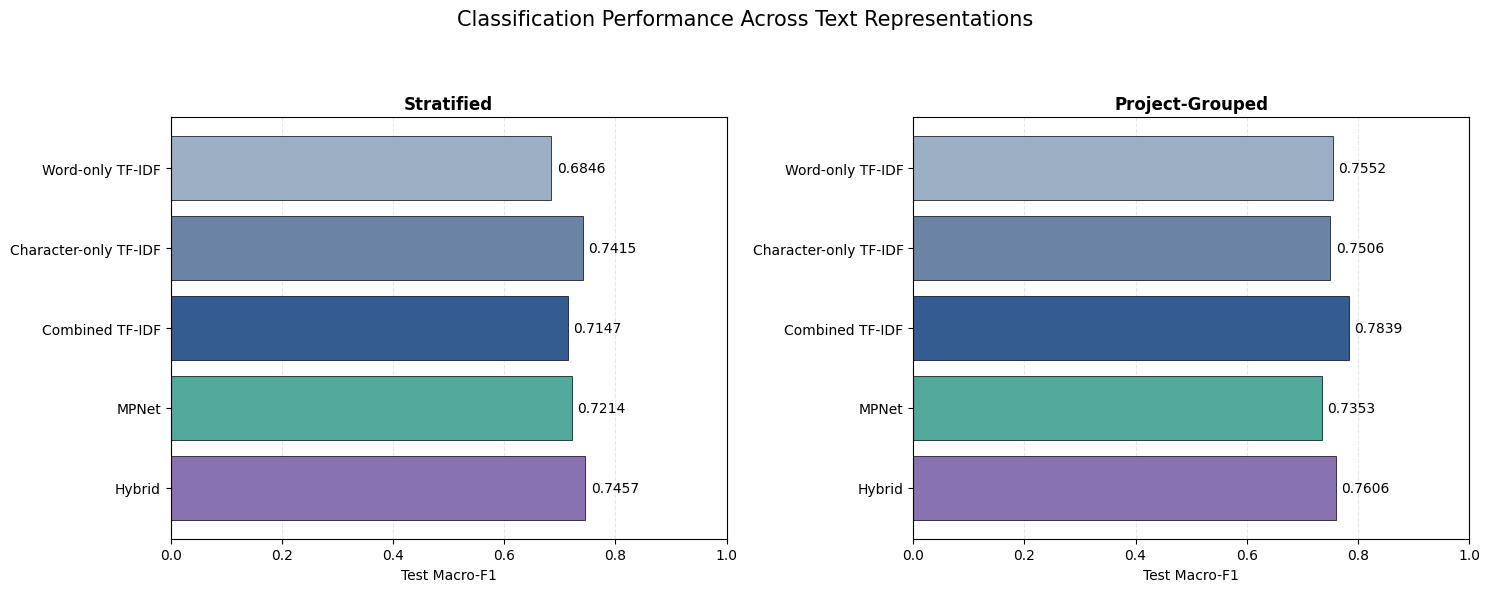

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\all_models_macro_f1_comparison.png


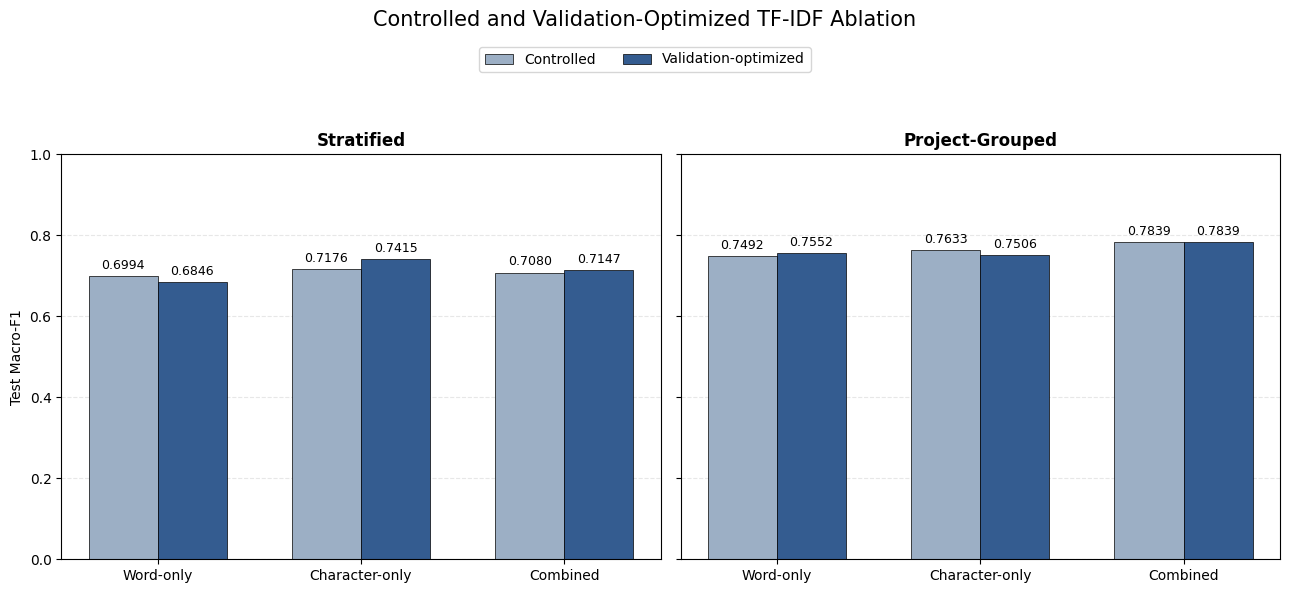

Figure saved to: d:\uOttawa\Fall_26\CSI5187\project\results\figures\tfidf_ablation_comparison.png


In [23]:
# Final comparative visualization across all representations

model_colors = {"word_only": "#9CAFC5","char_only": "#6B83A5","word_char": "#345C90","semantic": "#50A99A","hybrid": "#8872B0"}
fig, axes = plt.subplots(1, 2,figsize=(15, 6),sharex=True)

for ax, split_type in zip(axes, SPLITS):
    subset = (all_models_df[all_models_df["split"].eq(split_type)].set_index("model").reindex(model_order))
    bars = ax.barh([model_labels[m] for m in model_order], subset["macro_f1"], color=[model_colors[m] for m in model_order], edgecolor="black",linewidth=0.5)
    ax.bar_label(bars,fmt="%.4f",padding=4,fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(split_type.replace("_", "-").title(), fontweight="bold" )
    ax.set_xlabel("Test Macro-F1")
    ax.set_axisbelow(True)
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle( "Classification Performance Across Text Representations",fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.92])
figure_path = (RESULTS_DIR / "figures" / "all_models_macro_f1_comparison.png")
fig.savefig(figure_path,dpi=300,bbox_inches="tight",facecolor="white")
plt.show()
print("Figure saved to:", figure_path)


# Controlled versus independently optimized ablation

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
ablation_order = [ "word_only","char_only","word_char"]
x = np.arange(len(ablation_order))
width = 0.34

for ax, split_type in zip(axes, SPLITS):
    controlled = ( controlled_ablation_df[ controlled_ablation_df["split"].eq(split_type)].set_index("variant").reindex(ablation_order))
    optimized = (ablation_df[ablation_df["split"].eq(split_type)].set_index("variant").reindex(ablation_order))
    bars_controlled = ax.bar(x - width / 2,controlled["macro_f1"],width,label="Controlled",color="#9CAFC5",edgecolor="black",linewidth=0.5)
    bars_optimized = ax.bar(x + width / 2,optimized["macro_f1"],width,label="Validation-optimized",color="#345C90", edgecolor="black", linewidth=0.5)
    ax.bar_label(bars_controlled,fmt="%.4f",padding=3,fontsize=9 )
    ax.bar_label(bars_optimized,fmt="%.4f", padding=3,fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([ "Word-only", "Character-only","Combined"])
    ax.set_title( split_type.replace("_", "-").title(),fontweight="bold")
    ax.set_ylim(0, 1)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

axes[0].set_ylabel("Test Macro-F1")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend( handles,labels,loc="upper center",bbox_to_anchor=(0.5, 0.93),ncol=2)
fig.suptitle("Controlled and Validation-Optimized TF-IDF Ablation",fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.86])
ablation_figure_path = (RESULTS_DIR / "figures"/ "tfidf_ablation_comparison.png")
fig.savefig(ablation_figure_path,dpi=300,bbox_inches="tight",facecolor="white")
plt.show()
print("Figure saved to:", ablation_figure_path)